In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

plt.style.use("seaborn-v0_8")
np.random.seed(42)

pd.set_option("display.precision", 6)
pd.set_option("display.max_rows", 200)


In [2]:
# Data
X = np.random.randint(100, size=100)
X[:10], len(X)


(array([51, 92, 14, 71, 60, 20, 82, 86, 74, 74], dtype=int32), 100)

In [3]:
# Range
range_X = np.ptp(X)
print("Range of X:", range_X)

# Mean
mu = np.mean(X)
print("Mean (mu) of X:", mu)

# MAD 
MAD = np.mean(np.abs(X - mu))
print("Mean absolute deviation (MAD) of X:", MAD)

# Variance / Std (population)
var_X = np.var(X)
std_X = np.std(X)
print("Variance of X:", var_X)
print("Standard deviation of X:", std_X)

# Semivariance / Semideviation (below mean)
lows = X[X <= mu]
semivar = np.mean((lows - mu) ** 2)
semidev = float(np.sqrt(semivar))
print("Semivariance of X (below mu):", semivar)
print("Semideviation of X (below mu):", semidev)

# Target semivariance / semideviation (below threshold B)
B = 60
lows_B = X[X <= B]
semivar_B = np.mean((lows_B - B) ** 2)
semidev_B = float(np.sqrt(semivar_B))
print("Target semivariance of X (below B=60):", semivar_B)
print("Target semideviation of X (below B=60):", semidev_B)


Range of X: 98
Mean (mu) of X: 50.54
Mean absolute deviation (MAD) of X: 24.826
Variance of X: 857.2284
Standard deviation of X: 29.278463074417004
Semivariance of X (below mu): 1035.0773777777779
Semideviation of X (below mu): 32.172618447645476
Target semivariance of X (below B=60): 1262.9661016949153
Target semideviation of X (below B=60): 35.53823436377946


In [4]:
# Итоговая таблица мер разброса для Variance Exercise 1

dispersion_table = pd.DataFrame(
    [
        ("Variance Ex1", "Range (max-min)", "ptp(X)", range_X, "ед. X", "np.ptp(X)"),
        ("Variance Ex1", "Mean", "mu", mu, "ед. X", "np.mean(X)"),
        ("Variance Ex1", "Mean absolute deviation", "MAD", MAD, "ед. X", "mean(|X - mu|)"),
        ("Variance Ex1", "Variance (population)", "Var", var_X, "(ед. X)^2", "mean((X-mu)^2)"),
        ("Variance Ex1", "Std (population)", "Std", std_X, "ед. X", "sqrt(Var)"),
        ("Variance Ex1", "Semivariance (X<=mu)", "SemiVar", semivar, "(ед. X)^2", "mean((X-mu)^2 | X<=mu)"),
        ("Variance Ex1", "Semideviation (X<=mu)", "SemiDev", semidev, "ед. X", "sqrt(SemiVar)"),
        ("Variance Ex1", "Target semivariance (X<=B)", "TSemiVar(B=60)", semivar_B, "(ед. X)^2", "mean((X-B)^2 | X<=B)"),
        ("Variance Ex1", "Target semideviation (X<=B)", "TSemiDev(B=60)", semidev_B, "ед. X", "sqrt(TSemiVar)"),
    ],
    columns=["Раздел", "Метрика", "Обозначение", "Значение", "Единицы", "Как считали"],
)

dispersion_table


,Раздел,Метрика,Обозначение,Значение,Единицы,Как считали
0,Variance Ex1,Range (max-min),ptp(X),98.000000,ед. X,np.ptp(X)
1,Variance Ex1,Mean,mu,50.540000,ед. X,np.mean(X)
2,Variance Ex1,Mean absolute deviation,MAD,24.826000,ед. X,mean(|X - mu|)
3,Variance Ex1,Variance (population),Var,857.228400,(ед. X)^2,mean((X-mu)^2)
4,Variance Ex1,Std (population),Std,29.278463,ед. X,sqrt(Var)
5,Variance Ex1,Semivariance (X<=mu),SemiVar,1035.077378,(ед. X)^2,mean((X-mu)^2 | X<=mu)
6,Variance Ex1,Semideviation (X<=mu),SemiDev,32.172618,ед. X,sqrt(SemiVar)
7,Variance Ex1,Target semivariance (X<=B),TSemiVar(B=60),1262.966102,(ед. X)^2,mean((X-B)^2 | X<=B)
8,Variance Ex1,Target semideviation (X<=B),TSemiDev(B=60),35.538234,ед. X,sqrt(TSemiVar)


In [5]:
def normal_mu(x: np.ndarray) -> float:
    """MLE estimator for Normal mean."""
    n = len(x)
    return float(np.sum(x) / n)


def normal_sigma(x: np.ndarray) -> float:
    """MLE estimator for Normal sigma with divisor n (not n-1)."""
    n = len(x)
    mu_hat = normal_mu(x)
    sigma2_hat = float(np.sum((x - mu_hat) ** 2) / n)
    return math.sqrt(sigma2_hat)


In [6]:
# Data
TRUE_MEAN = 40
TRUE_STD = 10
X_norm = np.random.normal(TRUE_MEAN, TRUE_STD, 10_000_000)

mu_hat = normal_mu(X_norm)
sigma_hat = normal_sigma(X_norm)
print("MLE mu_hat:", mu_hat)
print("MLE sigma_hat:", sigma_hat)

scipy_mu, scipy_sigma = stats.norm.fit(X_norm)
print("SciPy norm.fit loc:", scipy_mu)
print("SciPy norm.fit scale:", scipy_sigma)

print("abs diff mu:", abs(mu_hat - scipy_mu))
print("abs diff sigma:", abs(sigma_hat - scipy_sigma))


MLE mu_hat: 40.0008516020034
MLE sigma_hat: 10.000553952579049
SciPy norm.fit loc: 40.0008516020034
SciPy norm.fit scale: 10.000553952579049
abs diff mu: 0.0
abs diff sigma: 0.0


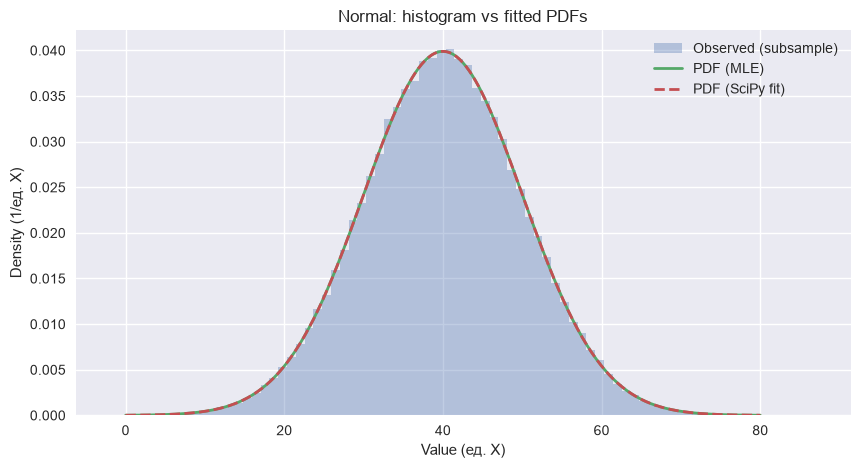

In [7]:
# Plot PDF over histogram (use a subsample for plotting speed)

plot_sample = X_norm[:200_000]

x_grid = np.linspace(mu_hat - 4 * sigma_hat, mu_hat + 4 * sigma_hat, 400)

plt.figure(figsize=(10, 5))
plt.hist(plot_sample, bins=80, density=True, alpha=0.35, label="Observed (subsample)")
plt.plot(x_grid, stats.norm.pdf(x_grid, loc=mu_hat, scale=sigma_hat), lw=2, label="PDF (MLE)")
plt.plot(x_grid, stats.norm.pdf(x_grid, loc=scipy_mu, scale=scipy_sigma), lw=2, linestyle="--", label="PDF (SciPy fit)")
plt.title("Normal: histogram vs fitted PDFs")
plt.xlabel("Value (ед. X)")
plt.ylabel("Density (1/ед. X)")
plt.legend()
plt.show()


In [8]:
def exp_scale_mle(x: np.ndarray) -> float:
    """MLE for Exponential scale (mean)."""
    return float(np.mean(x))


In [9]:
# Data 
TRUE_LAMBDA = 5 
X_exp = np.random.exponential(TRUE_LAMBDA, 1000)

scale_hat = exp_scale_mle(X_exp)
print("MLE scale_hat:", scale_hat)

loc_scipy, scale_scipy = stats.expon.fit(X_exp, floc=0)
print("SciPy expon.fit loc (fixed 0):", loc_scipy)
print("SciPy expon.fit scale:", scale_scipy)

print("abs diff scale:", abs(scale_hat - scale_scipy))


MLE scale_hat: 4.658053770296849
SciPy expon.fit loc (fixed 0): 0.0
SciPy expon.fit scale: 4.658053770296849
abs diff scale: 0.0


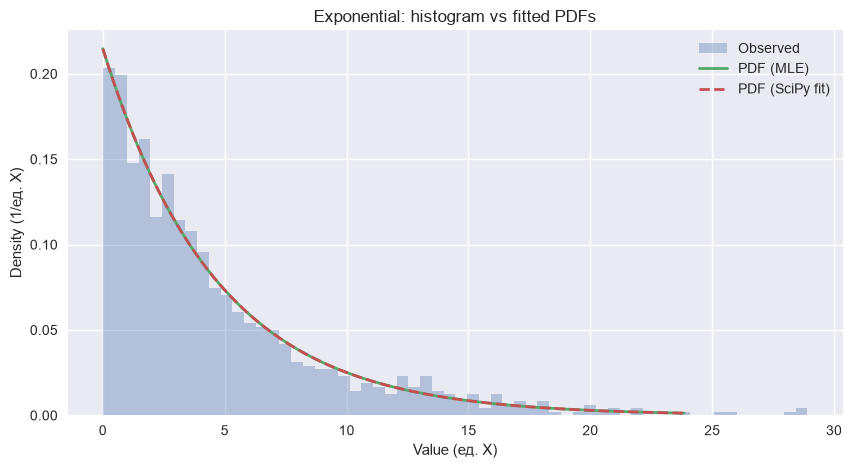

In [10]:
# Plot PDF over histogram

x_max = float(np.quantile(X_exp, 0.995))
x_grid = np.linspace(0, x_max, 400)

plt.figure(figsize=(10, 5))
plt.hist(X_exp, bins=60, density=True, alpha=0.35, label="Observed")
plt.plot(x_grid, stats.expon.pdf(x_grid, loc=0, scale=scale_hat), lw=2, label="PDF (MLE)")
plt.plot(x_grid, stats.expon.pdf(x_grid, loc=0, scale=scale_scipy), lw=2, linestyle="--", label="PDF (SciPy fit)")
plt.title("Exponential: histogram vs fitted PDFs")
plt.xlabel("Value (ед. X)")
plt.ylabel("Density (1/ед. X)")
plt.legend()
plt.show()


In [11]:
# Итоговая таблица оценок параметров

mle_table = pd.DataFrame(
    [
        ("MLE Ex1 (Normal)", "True mean", "mu_true", TRUE_MEAN, "ед. X", "генератор данных"),
        ("MLE Ex1 (Normal)", "True std", "sigma_true", TRUE_STD, "ед. X", "генератор данных"),
        ("MLE Ex1 (Normal)", "MLE mean", "mu_hat", mu_hat, "ед. X", "(1/n) * sum(x)"),
        ("MLE Ex1 (Normal)", "MLE std", "sigma_hat", sigma_hat, "ед. X", "sqrt((1/n)*sum((x-mu_hat)^2))"),
        ("MLE Ex1 (Normal)", "SciPy fit loc", "loc", scipy_mu, "ед. X", "stats.norm.fit"),
        ("MLE Ex1 (Normal)", "SciPy fit scale", "scale", scipy_sigma, "ед. X", "stats.norm.fit"),
        ("MLE Ex2 (Expon)", "True scale (mean)", "scale_true", TRUE_LAMBDA, "ед. X", "генератор данных"),
        ("MLE Ex2 (Expon)", "MLE scale", "scale_hat", scale_hat, "ед. X", "mean(x)"),
        ("MLE Ex2 (Expon)", "SciPy fit scale", "scale", scale_scipy, "ед. X", "stats.expon.fit(floc=0)"),
    ],
    columns=["Раздел", "Параметр", "Обозначение", "Значение", "Единицы", "Как считали"],
)

mle_table


,Раздел,Параметр,Обозначение,Значение,Единицы,Как считали
0,MLE Ex1 (Normal),True mean,mu_true,40.000000,ед. X,генератор данных
1,MLE Ex1 (Normal),True std,sigma_true,10.000000,ед. X,генератор данных
2,MLE Ex1 (Normal),MLE mean,mu_hat,40.000852,ед. X,(1/n) * sum(x)
3,MLE Ex1 (Normal),MLE std,sigma_hat,10.000554,ед. X,sqrt((1/n)*sum((x-mu_hat)^2))
4,MLE Ex1 (Normal),SciPy fit loc,loc,40.000852,ед. X,stats.norm.fit
5,MLE Ex1 (Normal),SciPy fit scale,scale,10.000554,ед. X,stats.norm.fit
6,MLE Ex2 (Expon),True scale (mean),scale_true,5.000000,ед. X,генератор данных
7,MLE Ex2 (Expon),MLE scale,scale_hat,4.658054,ед. X,mean(x)
8,MLE Ex2 (Expon),SciPy fit scale,scale,4.658054,ед. X,stats.expon.fit(floc=0)


In [12]:
final_table = pd.concat([dispersion_table, mle_table], ignore_index=True)
final_table


,Раздел,Метрика,Обозначение,Значение,Единицы,Как считали,Параметр
0,Variance Ex1,Range (max-min),ptp(X),98.000000,ед. X,np.ptp(X),NaN
1,Variance Ex1,Mean,mu,50.540000,ед. X,np.mean(X),NaN
2,Variance Ex1,Mean absolute deviation,MAD,24.826000,ед. X,mean(|X - mu|),NaN
3,Variance Ex1,Variance (population),Var,857.228400,(ед. X)^2,mean((X-mu)^2),NaN
4,Variance Ex1,Std (population),Std,29.278463,ед. X,sqrt(Var),NaN
5,Variance Ex1,Semivariance (X<=mu),SemiVar,1035.077378,(ед. X)^2,mean((X-mu)^2 | X<=mu),NaN
6,Variance Ex1,Semideviation (X<=mu),SemiDev,32.172618,ед. X,sqrt(SemiVar),NaN
7,Variance Ex1,Target semivariance (X<=B),TSemiVar(B=60),1262.966102,(ед. X)^2,mean((X-B)^2 | X<=B),NaN
8,Variance Ex1,Target semideviation (X<=B),TSemiDev(B=60),35.538234,ед. X,sqrt(TSemiVar),NaN
9,MLE Ex1 (Normal),NaN,mu_true,40.000000,ед. X,генератор данных,True mean
